# Brazilian E-Commerce: Exploratory Data Analysis & Business Insights

**Dataset:** [Olist Brazilian E-Commerce](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle)  |  **Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn

---

## 1. Project Overview

**Objective.** Explore Brazilian e-commerce transactional data to understand order performance, product sales, customer distribution, and delivery operations, and identify actionable business insights through Python-based exploratory data analysis.

**Business questions**

1. How are orders distributed by status, and how many reach the customer?
2. What does a typical order look like (value, shipping cost) and how skewed is the distribution?
3. Which product categories and individual products drive sales volume and revenue?
4. Where are customers located, and does order value differ across states?
5. Is freight cost related to product price?
6. *(New section)* How do orders evolve over time, and how long does delivery take compared with the estimate?

**Tables used (5 of the 9 Olist tables):** `orders`, `order_items`, `products`, `customers`, `payments`.




## 2. Setup & Data Loading

The data is downloaded from Kaggle with `kagglehub`, so the raw CSV files are **not** stored in this repository.

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub

path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

c:\Users\dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\dell\.cache\kagglehub\datasets\olistbr\brazilian-ecommerce\versions\2


In [3]:
files = os.listdir(path)
print(files)

['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [4]:
# os.path.join handles OS-specific path separators automatically
orders      = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
order_items = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
products    = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))
customers   = pd.read_csv(os.path.join(path, "olist_customers_dataset.csv"))
payments    = pd.read_csv(os.path.join(path, "olist_order_payments_dataset.csv"))

## 3. Data Understanding

Table sizes, a first look at each table, column names and data types.

In [5]:
datasets = {
    "orders": orders,
    "order_items": order_items,
    "products": products,
    "customers": customers,
    "payments": payments
}

for name, df in datasets.items():
    print(name, ":", df.shape)

orders : (99441, 8)
order_items : (112650, 7)
products : (32951, 9)
customers : (99441, 5)
payments : (103886, 5)


In [6]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [8]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [9]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.columns.tolist())


orders
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

order_items
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

products
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

customers
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

payments
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']


In [10]:
print("\n","-" * 25,"orders info", "-" * 25)
orders.info()

print("\n","-" * 25,"order items info", "-" * 25)
order_items.info()

print("\n","-" * 25,"products info", "-" * 25)
products.info()

print("\n","-" * 25,"customers info", "-" * 25)
customers.info()

print("\n","-" * 25,"payments info", "-" * 25)
payments.info()


 ------------------------- orders info -------------------------
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

 ------------------------- order items info -------------------------
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  

## 4. Data Quality & Preparation

### 4.1 Missing values and duplicates

In [11]:
# Missing values per table
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.isna().sum())


orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

order_items
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

products
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

customers
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state

In [12]:
# checking for duplicates
for name, df in datasets.items():
    print(name, "duplicates:", df.duplicated().sum())

orders duplicates: 0
order_items duplicates: 0
products duplicates: 0
customers duplicates: 0
payments duplicates: 0


**What the checks show**

- No table contains fully duplicated rows.
- `orders`: missing `order_approved_at` (160), `order_delivered_carrier_date` (1,783) and `order_delivered_customer_date` (2,965). These are expected for orders that have not reached those stages (e.g. shipped, canceled, unavailable), so they are **kept, not dropped**.
- `products`: 610 rows have no category, name length, description length or photo count, and 2 rows have no weight/dimensions. They are **left as `NaN`**; pandas `groupby` excludes them from category-level figures.

### 4.2 Key and relationship checks  

In [13]:
# Primary keys should be unique
print("orders.order_id unique        :", orders["order_id"].is_unique)
print("customers.customer_id unique  :", customers["customer_id"].is_unique)
print("products.product_id unique    :", products["product_id"].is_unique)

# Foreign keys should all find a parent row (0 = no orphans)
print("\norder_items -> orders   orphans:", (~order_items["order_id"].isin(orders["order_id"])).sum())
print("order_items -> products orphans:", (~order_items["product_id"].isin(products["product_id"])).sum())
print("orders -> customers     orphans:", (~orders["customer_id"].isin(customers["customer_id"])).sum())

# How many item rows are affected by a missing product category?
missing_cat_ids = products.loc[products["product_category_name"].isna(), "product_id"]
n_missing = order_items["product_id"].isin(missing_cat_ids).sum()
print(f"\nItem rows with no category: {n_missing:,} of {len(order_items):,} ({n_missing/len(order_items):.2%})")

orders.order_id unique        : True
customers.customer_id unique  : True
products.product_id unique    : True

order_items -> orders   orphans: 0
order_items -> products orphans: 0
orders -> customers     orphans: 0

Item rows with no category: 1,603 of 112,650 (1.42%)


### 4.3 Data types and working copies

In [14]:
orders[
    [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].dtypes



order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [15]:
# convert data type from object to datetime to answer questions like "How many days did it take to deliver an order?"
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [16]:
products.isna().sum()



product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [17]:
# Good habit: keep the raw data untouched and work on copies
orders_clean      = orders.copy()
order_items_clean = order_items.copy()
products_clean    = products.copy()
customers_clean   = customers.copy()
payments_clean    = payments.copy()

## 5. Order Analysis

### 5.1 Order status

In [18]:
orders_clean["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [19]:
# normalize=True returns each status as a share of all orders; x100 turns it into a percentage
orders_clean["order_status"].value_counts(normalize=True) * 100

order_status
delivered      97.020344
shipped         1.113223
canceled        0.628513
unavailable     0.612423
invoiced        0.315765
processing      0.302692
created         0.005028
approved        0.002011
Name: proportion, dtype: float64

**Reading:** 96,478 of 99,441 orders (**97.02%**) are `delivered`. Canceled (625) and unavailable (609) orders are each about 0.6%.

### 5.2 Item prices

In [20]:
print("Mean for items' price -> ", order_items_clean["price"].mean())
print("Median for items' price -> ", order_items_clean["price"].median())
print("Max for items' price -> ", order_items_clean["price"].max())
print("Min for items' price -> ", order_items_clean["price"].min())


Mean for items' price ->  120.65373901464713
Median for items' price ->  74.99
Max for items' price ->  6735.0
Min for items' price ->  0.85


In [21]:
# The most expensive items
order_items_clean.sort_values("price", ascending=False).head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,1,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,2017-02-16 20:37:36,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,1,69c590f7ffc7bf8db97190b6cb6ed62e,80ceebb4ee9b31afb6c6a916a574a1e2,2018-08-02 04:05:13,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1,1bdf5e6731585cf01aa8169c7028d6ad,ee27a8f15b1dded4d213a468ba4eb391,2017-06-15 02:45:17,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,1,a6492cc69376c469ab6f61d8f44de961,59417c56835dd8e2e72f91f809cd4092,2017-04-18 13:25:18,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,1,c3ed642d592594bb648ff4a04cee2747,59417c56835dd8e2e72f91f809cd4092,2017-05-09 15:50:15,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,1,259037a6a41845e455183f89c5035f18,c72de06d72748d1a0dfb2125be43ba63,2018-06-28 12:36:36,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,1,a1beef8f3992dbd4cd8726796aa69c53,512d298ac2a96d1931b6bd30aa21f61d,2018-08-16 14:24:28,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,1,6cdf8fc1d741c76586d8b6b15e9eef30,ed4acab38528488b65a9a9c603ff024a,2018-04-05 08:27:27,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,1,dd113cb02b2af9c8e5787e8f1f0722f6,821fb029fc6e495ca4f08a35d51e53a5,2018-08-02 08:15:14,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,1,6902c1962dd19d540807d0ab8fade5c6,fa1c13f2614d7b5c4749cbc52fecda94,2017-03-23 20:08:04,3999.90,17.01


**Per-order aggregation.** An order can contain several items, so prices are summed per `order_id`.

In [22]:
# the average price for each order
order_items_clean.groupby("order_id")["price"].mean()

order_id
00010242fe8c5a6d1ba2dd792cb16214     58.90
00018f77f2f0320c557190d7a144bdd3    239.90
000229ec398224ef6ca0657da4fc703e    199.00
00024acbcdf0a6daa1e931b038114c75     12.99
00042b26cf59d7ce69dfabb4e55b4fd9    199.90
                                     ...  
fffc94f6ce00a00581880bf54a75a037    299.99
fffcd46ef2263f404302a634eb57f7eb    350.00
fffce4705a9662cd70adb13d4a31832d     99.90
fffe18544ffabc95dfada21779c9644f     55.99
fffe41c64501cc87c801fd61db3f6244     43.00
Name: price, Length: 98666, dtype: float64

In [23]:
# the total price of products for each order
order_items_clean.groupby("order_id")["price"].sum()

order_id
00010242fe8c5a6d1ba2dd792cb16214     58.90
00018f77f2f0320c557190d7a144bdd3    239.90
000229ec398224ef6ca0657da4fc703e    199.00
00024acbcdf0a6daa1e931b038114c75     12.99
00042b26cf59d7ce69dfabb4e55b4fd9    199.90
                                     ...  
fffc94f6ce00a00581880bf54a75a037    299.99
fffcd46ef2263f404302a634eb57f7eb    350.00
fffce4705a9662cd70adb13d4a31832d     99.90
fffe18544ffabc95dfada21779c9644f     55.99
fffe41c64501cc87c801fd61db3f6244     43.00
Name: price, Length: 98666, dtype: float64

In [24]:
# the number of products in each order
order_items_clean.groupby("order_id")["product_id"].count()

order_id
00010242fe8c5a6d1ba2dd792cb16214    1
00018f77f2f0320c557190d7a144bdd3    1
000229ec398224ef6ca0657da4fc703e    1
00024acbcdf0a6daa1e931b038114c75    1
00042b26cf59d7ce69dfabb4e55b4fd9    1
                                   ..
fffc94f6ce00a00581880bf54a75a037    1
fffcd46ef2263f404302a634eb57f7eb    1
fffce4705a9662cd70adb13d4a31832d    1
fffe18544ffabc95dfada21779c9644f    1
fffe41c64501cc87c801fd61db3f6244    1
Name: product_id, Length: 98666, dtype: int64

In [25]:
order_items_clean.groupby("order_id")["price"].agg(
    ["sum", "mean", "min", "max"]
)

,sum,mean,min,max
order_id,,,,
00010242fe8c5a6d1ba2dd792cb16214,58.90,58.90,58.90,58.90
00018f77f2f0320c557190d7a144bdd3,239.90,239.90,239.90,239.90
000229ec398224ef6ca0657da4fc703e,199.00,199.00,199.00,199.00
00024acbcdf0a6daa1e931b038114c75,12.99,12.99,12.99,12.99
00042b26cf59d7ce69dfabb4e55b4fd9,199.90,199.90,199.90,199.90
...,...,...,...,...
fffc94f6ce00a00581880bf54a75a037,299.99,299.99,299.99,299.99
fffcd46ef2263f404302a634eb57f7eb,350.00,350.00,350.00,350.00
fffce4705a9662cd70adb13d4a31832d,99.90,99.90,99.90,99.90


### 5.3 Price statistics with NumPy

In [26]:
# to get orders prices as Numpy Array
prices = order_items_clean["price"].to_numpy()
print(prices)

[ 58.9  239.9  199.   ...  99.9   55.99  43.  ]


In [27]:
print(f"Mean   : {np.mean(prices)}")
print(f"Median : {np.median(prices)}")
print(f"Std    : {np.std(prices)}")
print(f"Min    : {np.min(prices)}")
print(f"Max    : {np.max(prices)}")

Mean   : 120.65373901464713
Median : 74.99
Std    : 183.63311298441127
Min    : 0.85
Max    : 6735.0


In [28]:
# Percentiles
print(np.percentile(prices , 25),
np.percentile(prices , 50),
np.percentile(prices , 75), sep="\n")

39.9
74.99
134.9


In [29]:
# discovering outliers using IQR
Q1 = np.percentile(prices, 25)
Q3 = np.percentile(prices, 75)
IQR = Q3 - Q1

# Finding outliers limits
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# to know how many prices consider an OUTLIER
outliers = prices[
    (prices < lower_bound) |
    (prices > upper_bound)
]

len(outliers)

Q1: 39.9
Q3: 134.9
IQR: 95.0
Lower Bound: -102.6
Upper Bound: 277.4


8427

**Reading:** the mean item price (R$120.65) is well above the median (R$74.99) and the maximum is R$6,735.00. By the 1.5×IQR rule, **8,427 items** fall outside the bounds. The price distribution is strongly right-skewed.

### 5.4 Order value and shipping per order

In [ ]:
# Calculating the total value of each Order
# that order_items can contain more than one product in the same order
# So, we will need to sum the product prices within each order_id.

order_totals = (
    order_items_clean
    .groupby("order_id")["price"]
    .sum()
    .reset_index(name="total_order_value")  # .reset_index() --> We converted the result into an organized DataFrame.
)                                           # name="total_order_value" --> we renamed the new column "total_order_value"

order_totals.head()


,order_id,total_order_value
0,00010242fe8c5a6d1ba2dd792cb16214,58.90
1,00018f77f2f0320c557190d7a144bdd3,239.90
2,000229ec398224ef6ca0657da4fc703e,199.00
3,00024acbcdf0a6daa1e931b038114c75,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90


In [31]:
average_order_value = order_totals["total_order_value"].mean()

print("Average Order Value:", average_order_value)

Average Order Value: 137.75407637889444


In [32]:
# Top 5 orders by product value
top_orders = order_totals.sort_values("total_order_value", ascending=False).head()
top_orders

,order_id,total_order_value
1455,03caa2c082116e1d31e67e9ae3700499,13440.0
44467,736e1922ae60d0d6a89247b851902527,7160.0
3130,0812eb902a67711a1cb742b3cdaa65ae,6735.0
98298,fefacc66af859508bf1a7934eab1e97f,6729.0
94439,f5136e38d1a14a4dbd87dff67da82701,6499.0


In [33]:
# Adding shipping cost -- calculating the total shipping cost for each order
order_shipping = (
    order_items_clean.groupby("order_id")["freight_value"].sum()
    .reset_index(name="total_shipping")
)

order_shipping.head()

,order_id,total_shipping
0,00010242fe8c5a6d1ba2dd792cb16214,13.29
1,00018f77f2f0320c557190d7a144bdd3,19.93
2,000229ec398224ef6ca0657da4fc703e,17.87
3,00024acbcdf0a6daa1e931b038114c75,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,18.14


In [34]:
# Create order_analysis by merging order_totals with order_shipping using a left join on order_id
order_analysis = order_totals.merge(
    order_shipping,  # Merge with the shipping summary table
    on="order_id",  # Join on the primary key: order_id
    how="left",  # Keep all rows from order_totals even if shipping info is missing
)

order_analysis.head()

,order_id,total_order_value,total_shipping
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14


In [35]:
# Calculating the total value including shipping
order_analysis["total_with_shipping"] = (
    order_analysis["total_order_value"]
    + order_analysis["total_shipping"]
)

order_analysis.head()

,order_id,total_order_value,total_shipping,total_with_shipping
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,72.19
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,259.83
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,216.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,218.04


In [36]:
average_total_with_shipping = (
    order_analysis["total_with_shipping"].mean()
)

print(
    "Average Order Value Including Shipping:",
    average_total_with_shipping
)

Average Order Value Including Shipping: 160.57763809214924


In [37]:
order_analysis[
    ["total_order_value", "total_shipping", "total_with_shipping"]
].describe()

,total_order_value,total_shipping,total_with_shipping
count,98666.000000,98666.000000,98666.000000
mean,137.754076,22.823562,160.577638
std,210.645145,21.650909,220.466087
min,0.850000,0.000000,9.590000
25%,45.900000,13.850000,61.980000
50%,86.900000,17.170000,105.290000
75%,149.900000,24.040000,176.870000
max,13440.000000,1794.960000,13664.080000


**Reading (98,666 orders with items):** average order value is **R$137.75** vs. a median of **R$86.90**; the largest order is R$13,440. Adding shipping lifts the average total to **R$160.58**.

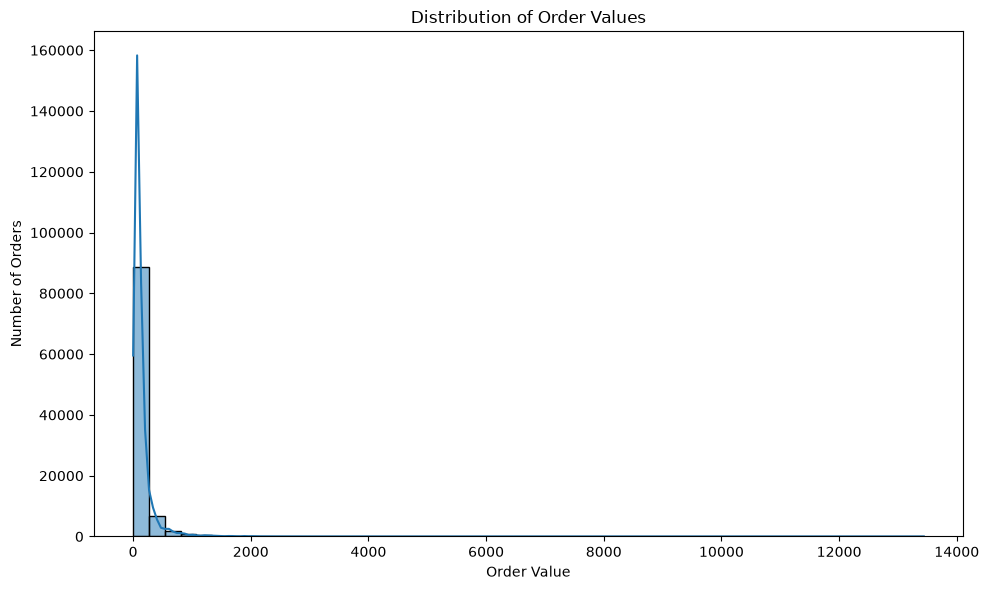

In [38]:
plt.figure(figsize=(10, 6))

sns.histplot(
    order_analysis["total_order_value"],
    bins=50,
    kde=True
)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

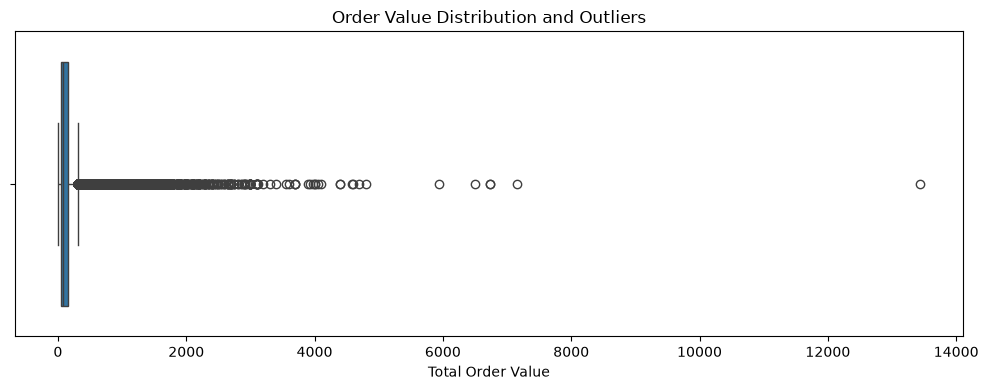

In [39]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=order_analysis["total_order_value"]
)

plt.title("Order Value Distribution and Outliers")
plt.xlabel("Total Order Value")

plt.tight_layout()
plt.show()

### 5.5 Orders and revenue over time 

Purchase dates range: 2016-09-04 -> 2018-10-17


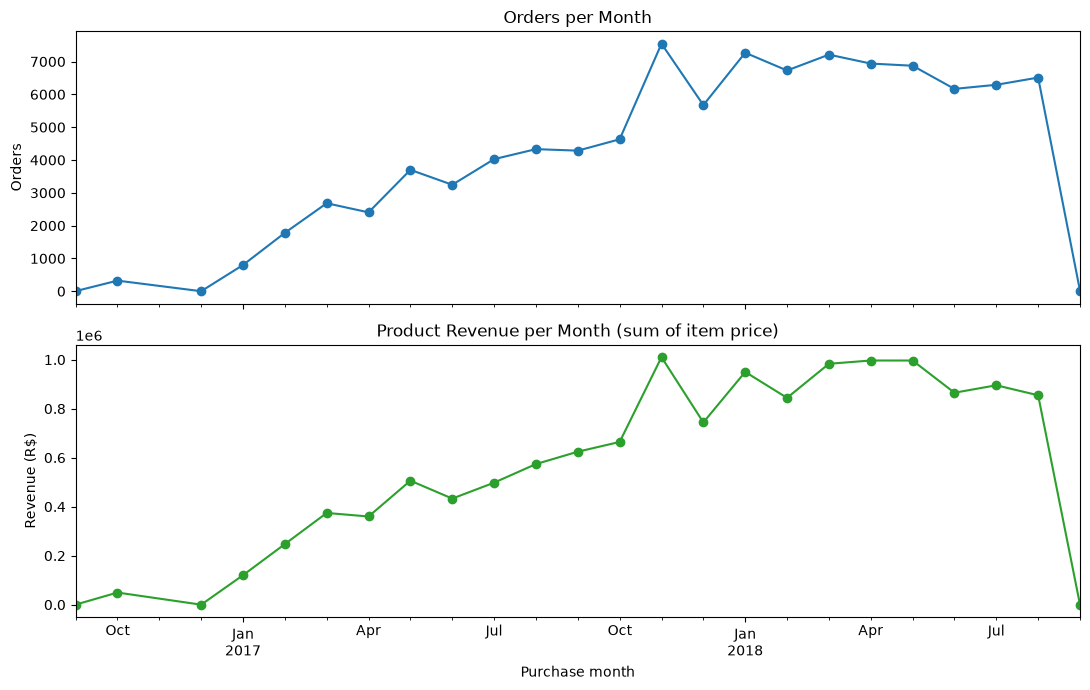

In [ ]:
print("Purchase dates range:",
        orders_clean["order_purchase_timestamp"].min().date(), "->",
        orders_clean["order_purchase_timestamp"].max().date())

orders_clean["purchase_month"] = orders_clean["order_purchase_timestamp"].dt.to_period("M")

monthly_orders = orders_clean.groupby("purchase_month").size()

# Revenue = sum of item price, attributed to the order's purchase month
monthly_revenue = (
    order_items_clean
    .merge(orders_clean[["order_id", "purchase_month"]], on="order_id", how="left")
    .groupby("purchase_month")["price"].sum()
)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
monthly_orders.plot(ax=axes[0], marker="o")
axes[0].set_title("Orders per Month")
axes[0].set_ylabel("Orders")

monthly_revenue.plot(ax=axes[1], marker="o", color="tab:green")
axes[1].set_title("Product Revenue per Month (sum of item price)")
axes[1].set_ylabel("Revenue (R$)")
axes[1].set_xlabel("Purchase month")

plt.tight_layout()
plt.show()

## 6. Product & Category Analysis

Category names come from the dataset in Portuguese (e.g. `beleza_saude` = health & beauty, `cama_mesa_banho` = bed, bath & table).

### 6.1 Best-selling products and categories (by times sold)

In [41]:
# Most sold products in terms of number of appearances
product_sales = (
    order_items_clean
    .groupby("product_id")
    .size()                   # We count the number of rows for each product.
    .reset_index(name="times_sold")
)

product_sales = product_sales.sort_values(
    "times_sold",
    ascending=False
)

product_sales.head(10)

,product_id,times_sold
22112,aca2eb7d00ea1a7b8ebd4e68314663af,527
19742,99a4788cb24856965c36a24e339b6058,488
8613,422879e10f46682990de24d770e7f83d,484
7364,389d119b48cf3043d311335e499d9c6b,392
7079,368c6c730842d78016ad823897a372db,388
10840,53759a2ecddad2bb87a079a1f1519f73,373
27039,d1c427060a0f73f6b889a5c7c61f2ac4,343
10867,53b36df67ebb7c41585e8d54d6772e08,323
2794,154e7e31ebfa092203795c972e5804a6,281
8051,3dd2a17168ec895c781a9191c1e95ad7,274


In [42]:
product_sales_details = product_sales.merge(
    products_clean[
        ["product_id", "product_category_name"]
    ],
    on="product_id",
    how="left"
)

product_sales_details.head(10)

,product_id,times_sold,product_category_name
0,aca2eb7d00ea1a7b8ebd4e68314663af,527,moveis_decoracao
1,99a4788cb24856965c36a24e339b6058,488,cama_mesa_banho
2,422879e10f46682990de24d770e7f83d,484,ferramentas_jardim
3,389d119b48cf3043d311335e499d9c6b,392,ferramentas_jardim
4,368c6c730842d78016ad823897a372db,388,ferramentas_jardim
5,53759a2ecddad2bb87a079a1f1519f73,373,ferramentas_jardim
6,d1c427060a0f73f6b889a5c7c61f2ac4,343,informatica_acessorios
7,53b36df67ebb7c41585e8d54d6772e08,323,relogios_presentes
8,154e7e31ebfa092203795c972e5804a6,281,beleza_saude
9,3dd2a17168ec895c781a9191c1e95ad7,274,informatica_acessorios


In [43]:

# The most frequent categories in the orders
category_sales = (
    product_sales_details
    .groupby("product_category_name")["times_sold"]
    .sum()
    .reset_index()
    .sort_values("times_sold", ascending=False)
)

category_sales.head(10)

,product_category_name,times_sold
13,cama_mesa_banho,11115
11,beleza_saude,9670
32,esporte_lazer,8641
54,moveis_decoracao,8334
44,informatica_acessorios,7827
72,utilidades_domesticas,6964
66,relogios_presentes,5991
70,telefonia,4545
40,ferramentas_jardim,4347
8,automotivo,4235


### 6.2 Revenue by category

In [44]:
# Revenue by Product Category
# first
items_with_category = order_items_clean.merge(
    products_clean[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

items_with_category.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim


In [45]:
# calculating revenue for each category
category_revenue = (
    items_with_category
    .groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue.head(10)

product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
moveis_decoracao           729762.49
cool_stuff                 635290.85
utilidades_domesticas      632248.66
automotivo                 592720.11
ferramentas_jardim         485256.46
Name: price, dtype: float64

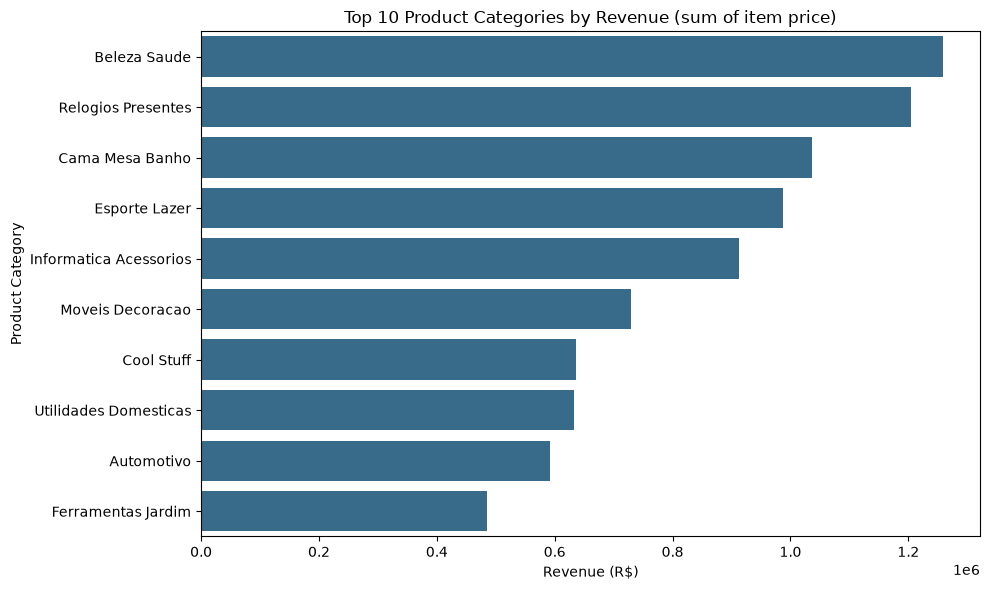

In [46]:
top_categories = category_revenue.head(10)
labels = top_categories.index.str.replace("_", " ").str.title()

plt.figure(figsize=(10, 6))
sns.barplot(x=top_categories.values, y=labels, color="#2a6f97")
plt.title("Top 10 Product Categories by Revenue (sum of item price)")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

**Reading:** Health & beauty (R$1,258,681) leads, followed by watches & gifts (R$1,205,006) and bed, bath & table (R$1,036,989). By *units sold* the order is different (bed, bath & table first with 11,115), so volume and revenue rank categories differently.

### 6.3 Product-level performance: volume vs. revenue

In [47]:
product_revenue = (
    order_items_clean
    .groupby("product_id")["price"]
    .sum()
    .reset_index(name="total_revenue")
    .sort_values("total_revenue", ascending=False)
)

product_revenue.head(10)

,product_id,total_revenue
24086,bb50f2e236e5eea0100680137654686c,63885.00
14068,6cdd53843498f92890544667809f1595,54730.20
27613,d6160fb7873f184099d9bc95e30376af,48899.34
27039,d1c427060a0f73f6b889a5c7c61f2ac4,47214.51
19742,99a4788cb24856965c36a24e339b6058,43025.56
8051,3dd2a17168ec895c781a9191c1e95ad7,41082.60
4996,25c38557cf793876c5abdd5931f922db,38907.32
12351,5f504b3a1c75b73d6151be81eb05bdc9,37733.90
10867,53b36df67ebb7c41585e8d54d6772e08,37683.42
22112,aca2eb7d00ea1a7b8ebd4e68314663af,37608.90


In [48]:
# comnining revenue with times_sold
product_performance = product_sales.merge(
    product_revenue,
    on="product_id",
    how="inner"
)

product_performance.head(10)

,product_id,times_sold,total_revenue
0,aca2eb7d00ea1a7b8ebd4e68314663af,527,37608.90
1,99a4788cb24856965c36a24e339b6058,488,43025.56
2,422879e10f46682990de24d770e7f83d,484,26577.22
3,389d119b48cf3043d311335e499d9c6b,392,21440.59
4,368c6c730842d78016ad823897a372db,388,21056.80
5,53759a2ecddad2bb87a079a1f1519f73,373,20387.20
6,d1c427060a0f73f6b889a5c7c61f2ac4,343,47214.51
7,53b36df67ebb7c41585e8d54d6772e08,323,37683.42
8,154e7e31ebfa092203795c972e5804a6,281,6325.19
9,3dd2a17168ec895c781a9191c1e95ad7,274,41082.60


In [49]:
product_performance_details = product_performance.merge(
    products_clean[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

product_performance_details.head(10)

,product_id,times_sold,total_revenue,product_category_name
0,aca2eb7d00ea1a7b8ebd4e68314663af,527,37608.90,moveis_decoracao
1,99a4788cb24856965c36a24e339b6058,488,43025.56,cama_mesa_banho
2,422879e10f46682990de24d770e7f83d,484,26577.22,ferramentas_jardim
3,389d119b48cf3043d311335e499d9c6b,392,21440.59,ferramentas_jardim
4,368c6c730842d78016ad823897a372db,388,21056.80,ferramentas_jardim
5,53759a2ecddad2bb87a079a1f1519f73,373,20387.20,ferramentas_jardim
6,d1c427060a0f73f6b889a5c7c61f2ac4,343,47214.51,informatica_acessorios
7,53b36df67ebb7c41585e8d54d6772e08,323,37683.42,relogios_presentes
8,154e7e31ebfa092203795c972e5804a6,281,6325.19,beleza_saude
9,3dd2a17168ec895c781a9191c1e95ad7,274,41082.60,informatica_acessorios


In [50]:
top_revenue_products = (
    product_performance_details
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

top_revenue_products

,product_id,times_sold,total_revenue,product_category_name
14,bb50f2e236e5eea0100680137654686c,195,63885.00,beleza_saude
21,6cdd53843498f92890544667809f1595,156,54730.20,beleza_saude
300,d6160fb7873f184099d9bc95e30376af,35,48899.34,pcs
6,d1c427060a0f73f6b889a5c7c61f2ac4,343,47214.51,informatica_acessorios
1,99a4788cb24856965c36a24e339b6058,488,43025.56,cama_mesa_banho
9,3dd2a17168ec895c781a9191c1e95ad7,274,41082.60,informatica_acessorios
269,25c38557cf793876c5abdd5931f922db,38,38907.32,bebes
119,5f504b3a1c75b73d6151be81eb05bdc9,63,37733.90,cool_stuff
7,53b36df67ebb7c41585e8d54d6772e08,323,37683.42,relogios_presentes
0,aca2eb7d00ea1a7b8ebd4e68314663af,527,37608.90,moveis_decoracao


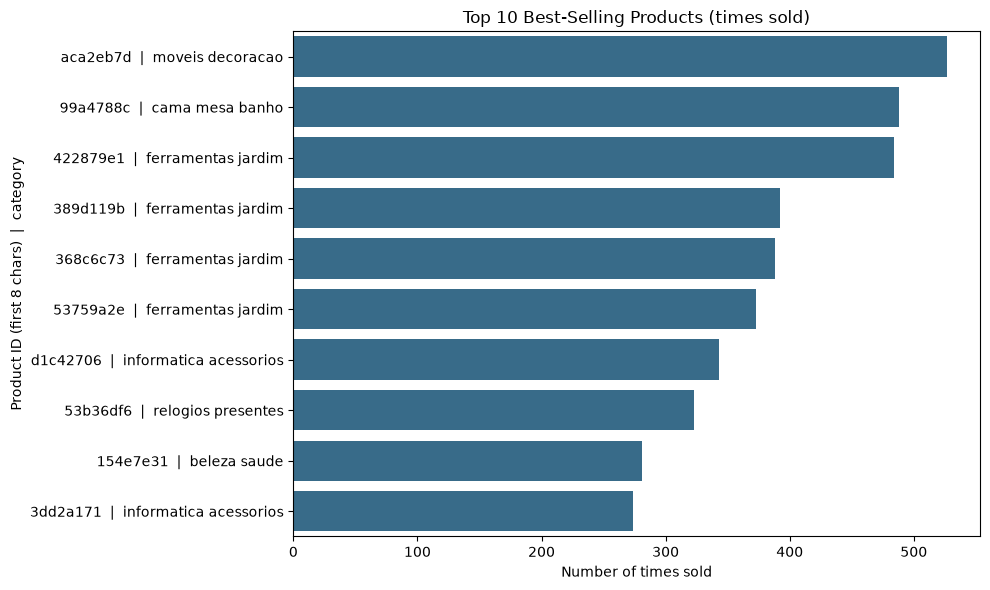

In [51]:
top_products = product_sales_details.head(10).copy()
top_products["label"] = (
    top_products["product_id"].str[:8] + "  |  "
    + top_products["product_category_name"].fillna("unknown").str.replace("_", " ")
)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_products, x="times_sold", y="label", color="#2a6f97")
plt.title("Top 10 Best-Selling Products (times sold)")
plt.xlabel("Number of times sold")
plt.ylabel("Product ID (first 8 chars)  |  category")
plt.tight_layout()
plt.show()

**Reading:** popularity and revenue do not line up. The product sold most often (527 times, home decor) is not the top earner. The top revenue product (R$63,885, health & beauty) was sold 195 times, while a product in `pcs` generated R$48,899 from only 35 sales.

## 7. Customer & Geographic Analysis

> `customer_id` in Olist is assigned **per order**, so counting rows in `customers` gives the same numbers as counting orders by state. The cell in 7.1 checks how many distinct people there actually are via `customer_unique_id`.

In [52]:
#Customer analysis by state (counting customers in each state)
customers_by_state = (
    customers_clean["customer_state"]
    .value_counts()
    .reset_index()
)

customers_by_state.columns = [
    "customer_state",
    "customer_count"
]

customers_by_state.head(10)

,customer_state,customer_count
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


In [53]:
# Linking customers to orders
orders_customers = orders_clean.merge(
    customers_clean[
        ["customer_id", "customer_unique_id", "customer_state"]
    ],
    on = "customer_id",
    how = "left"
)

orders_customers.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_month,customer_unique_id,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,7c396fd4830fd04220f754e42b4e5bff,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,af07308b275d755c9edb36a90c618231,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,7c142cf63193a1473d2e66489a9ae977,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,SP


In [54]:
#Number of orders by state

orders_by_state = (
    orders_customers["customer_state"]
    .value_counts()
    .reset_index()
)

orders_by_state.columns = [
    "customer_state",
    "order_count"
]

orders_by_state.head(10)


,customer_state,order_count
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


In [ ]:
# distinct customers (by customer_unique_id) vs. rows in customers
print("Rows in customers          :", len(customers_clean))
print("Distinct customer_unique_id:", customers_clean["customer_unique_id"].nunique())

Rows in customers          : 99441
Distinct customer_unique_id: 96096


### 7.2 Order value by state and by status

In [56]:
# Average order value by state

order_analysis_with_state = order_analysis.merge(
    orders_customers[
        ["order_id", "customer_state"]
    ],
    on = "order_id",
    how= "left"
)

state_order_value = (
    order_analysis_with_state
    .groupby("customer_state")["total_order_value"]
    .agg(["count", "mean", "sum"])
        .reset_index()
    .sort_values("mean", ascending=False)
)

state_order_value.head(10)

,customer_state,count,mean,sum
14,PB,532,216.669323,115268.08
3,AP,68,198.151471,13474.30
0,AC,81,197.320370,15982.95
1,AL,411,195.413163,80314.81
20,RO,247,186.804211,46140.64
13,PA,970,184.482278,178947.81
26,TO,279,177.855699,49621.74
16,PI,493,176.296308,86914.08
12,MT,903,173.259723,156453.53
19,RN,482,172.271743,83034.98


In [57]:
# Does the order value vary by order status? Meaning, what is the average value for delivered orders? And for canceled ones? And so on.

order_value_by_status = (
    order_analysis_with_state
    .merge(
        orders_clean[["order_id", "order_status"]],
        on = "order_id",
        how="left"
    )
    .groupby("order_status")["total_order_value"]
    .mean()
)

order_value_by_status

order_status
approved       104.800000
canceled       206.584100
delivered      137.041586
invoiced       197.199904
processing     200.794751
shipped        136.281591
unavailable    334.615000
Name: total_order_value, dtype: float64

**Reading:** São Paulo alone accounts for 41,746 of 99,441 orders (about 42%); SP, RJ and MG together account for 66,233 (about 67%). Paraíba (PB) has the highest average order value (R$216.67), but it is based on 532 orders, so compare it with state volumes before reading too much into it.
Average value by status (delivered R$137.04 vs. canceled R$206.58 and unavailable R$334.62) covers only orders that have items, and the non-delivered groups are small.

## 8. Delivery & Shipping Analysis

### 8.1 Is freight related to price?

In [58]:
# Do the more expensive products have higher shipping costs?
order_items_clean[
    ["price", "freight_value"]
].corr()

,price,freight_value
price,1.000000,0.414204
freight_value,0.414204,1.000000


In [59]:
# Another way to know if the more expensive products have higher shipping costs?
correlation = order_items_clean["price"].corr(
    order_items_clean["freight_value"]
)

print(correlation)

# if result near +1 so it's strong positive relationship

0.4142043103630353


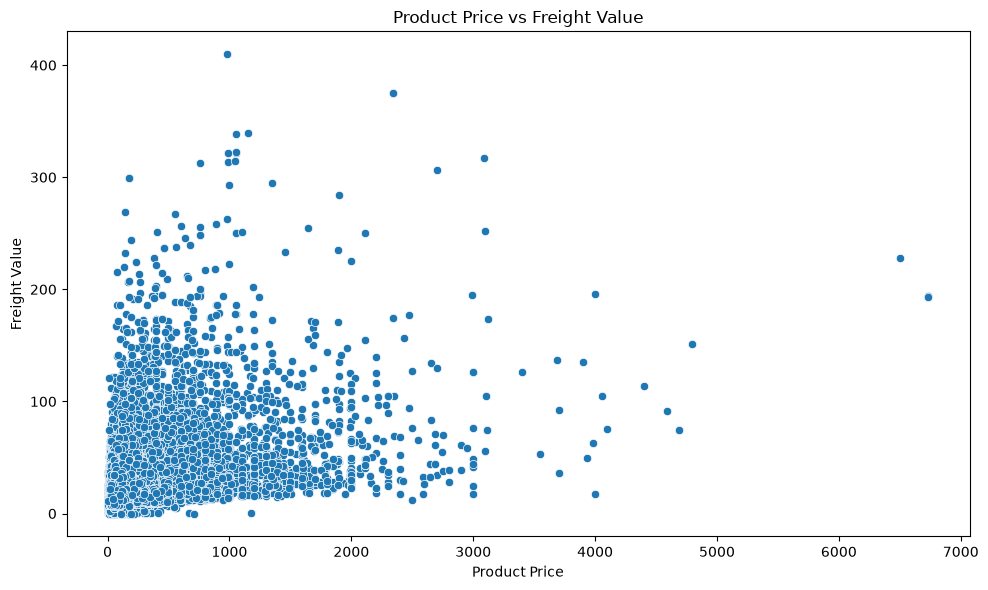

In [60]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=order_items_clean,
    x="price",
    y="freight_value"
)

plt.title("Product Price vs Freight Value")
plt.xlabel("Product Price")
plt.ylabel("Freight Value")

plt.tight_layout()
plt.show()

**Reading:** the correlation between item price and freight value is **0.41**, a moderate positive relationship: pricier items tend to cost more to ship, but price explains only part of freight cost (weight and distance, for example, are not included here).

### 8.2 Delivery time vs. estimate 

In [61]:
delivered = orders_clean[
    (orders_clean["order_status"] == "delivered")
    & orders_clean["order_delivered_customer_date"].notna()
].copy()

delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# positive = delivered after the estimated date
delivered["days_vs_estimate"] = (
    delivered["order_delivered_customer_date"] - delivered["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

print("Orders analysed:", len(delivered))
print(delivered["delivery_days"].describe().round(2))
print(f"\nDelivered after the estimated date: {(delivered['days_vs_estimate'] > 0).mean():.2%}")

Orders analysed: 96470
count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_days, dtype: float64

Delivered after the estimated date: 8.11%


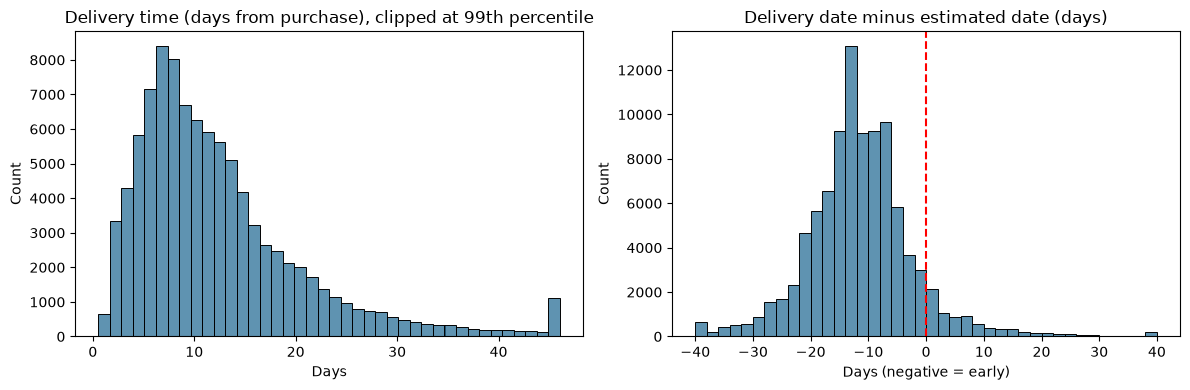

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(delivered["delivery_days"].clip(upper=delivered["delivery_days"].quantile(0.99)),
             bins=40, ax=axes[0], color="#2a6f97")
axes[0].set_title("Delivery time (days from purchase), clipped at 99th percentile")
axes[0].set_xlabel("Days")

sns.histplot(delivered["days_vs_estimate"].clip(lower=-40, upper=40),
             bins=40, ax=axes[1], color="#2a6f97")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Delivery date minus estimated date (days)")
axes[1].set_xlabel("Days (negative = early)")

plt.tight_layout()
plt.show()

In [63]:
# Average delivery time by customer state (states with >= 100 delivered orders)
delivered_state = delivered.merge(customers_clean[["customer_id", "customer_state"]],
                                  on="customer_id", how="left")
state_delivery = (
    delivered_state.groupby("customer_state")["delivery_days"]
    .agg(["count", "mean"]).query("count >= 100").sort_values("mean")
)
state_delivery.round(1)

,count,mean
customer_state,,
SP,40494,8.8
PR,4923,12.0
MG,11354,12.0
DF,2080,13.0
SC,3546,15.0
RS,5344,15.3
RJ,12350,15.3
GO,1957,15.6
MS,701,15.6


## 9. Business Insights & Recommendations

### Key findings (all figures come from the executed cells above)

1. **Order status:** 96,478 of 99,441 orders (97.02%) were delivered; 625 were canceled and 609 unavailable.
2. **Order value:** average R$137.75 vs. median R$86.90 across 98,666 orders with items. The mean is pulled up by a few large orders (max R$13,440).
3. **Shipping:** average freight per order is R$22.82, taking the average order total to R$160.58.
4. **Price vs. freight:** correlation of 0.41, moderate and positive.
5. **Categories:** health & beauty has the highest product revenue (about R$1.26M), followed by watches & gifts (R$1.21M) and bed, bath & table (R$1.04M). Bed, bath & table leads in units sold (11,115).
6. **Volume ≠ revenue:** the best-selling product (527 sales) is not the top earner, and a `pcs` product earned R$48.9K from only 35 sales.
7. **Geography:** São Paulo accounts for about 42% of orders; the average order value is highest in PB (R$216.67, 532 orders).

### Suggested next steps (hypotheses to test, not conclusions)

- Review high-revenue / low-volume products: they may be worth stocking and promoting differently from high-volume items.
- Because orders concentrate in SP, RJ and MG, check whether delivery time and freight cost differ in less-served states (see section 8.2).
- Look at the monthly view (section 5.5) before planning campaigns, to see whether demand is seasonal.

### Limitations

- "Revenue" is the sum of item prices: no costs, discounts, refunds or profit are included.
- Order-value statistics cover only orders that have items (98,666 of 99,441).
- Only 5 of the 9 Olist tables are used (reviews, sellers, geolocation and category translation are not).
- The analysis is descriptive. Correlation does not show cause, and no statistical tests or predictive models are used.
- Products with a missing category are excluded from category-level figures.